# Plagiarism Policy

NUS takes a strict view of plagiarism and considers it a serious form of academic dishonesty. Any student found to have engaged in such misconduct will be subjected to disciplinary action by the University. Please refer to the NUS Plagiarism Policy.

For assignments in BT4222, sharing any part of the solution among students is not allowed either. If assignments were caught with a high degree of similarity, suspects will be subjected to a plagarism investigation.

# BT4222 Assignment 1 Guideline (10% of your overall course assessment)

Due: Monday, September 07 at 12:00 PM
- **Read the Guideline:** Refer to the Assignment 1 Guideline for detailed instructions and the rubrics.
- **Understand the Structure** This assignment is divided into multiple steps to provide comprehensive practice with course concepts and mechanisms. Do understand the structure of the assignment and its concepts.
- **Answer at the end:** Fill in your answers at the **end of the assignment**. Explicitly specify which model and step(s) each answer refer to.
- **Code Quality Matters:** Write clean, well-organized code with clear variable names and logical structure. Add additional code cells as needed to improve readability and organization.
- **Display your outputs:** If you are supporting your solution with results, ensure its output is clearly printed and visible. Missing outputs may result in lost marks, as we cannot evaluate solutions without seeing the results.
- Teaching Assistant: Wong Zheng Tat <wongzhengtat@u.nus.edu>

# Context:

You will be playing the role of a data analyst tasked with improving the data preparation stages of the basic recommendation system models developed by the previous analyst. The first model is a basic recommendation system for a Fashion e-commerce platform. The second model is a video recommendation system for a social media platform. You are only given the source code for the **data preparation stage** of each model. However, these data piplines are intended for use in **downstream reccomendation models** in realistic production settings.

Your task will be to understand the current source code and identify 6 substantive issues with it.  Potential issues include errors, mistakes, assumptions, biases about the model, or missing or poorly constructed features. Stronger answers will (1) demonstrate critical thinking to identify critical limitations/assumptions, (2) suggest an alternative, and (3) explain its merits. Optionally, you can provide evidence (if possible) showing why your approach is better.


## Model 1: Fashion products reccomendation model

The fashion e-commerce platform currently collects various data points from customer transactions over a 1 month period and has a database of its fashion products. You will be provided with 2 datasets.
1. Transactions dataset (transactions_train.csv) which represents all the transactions made in the store.
2. Articles dataset (articles.csv) which represents all the items found in its catalog.

## Step 1: Downloading data procedures

Login into Kaggle Account -> Accept data rules on the competition and download directly from https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data **(You only need transactions_train.csv and articles.csv, do not download customer.csv)**

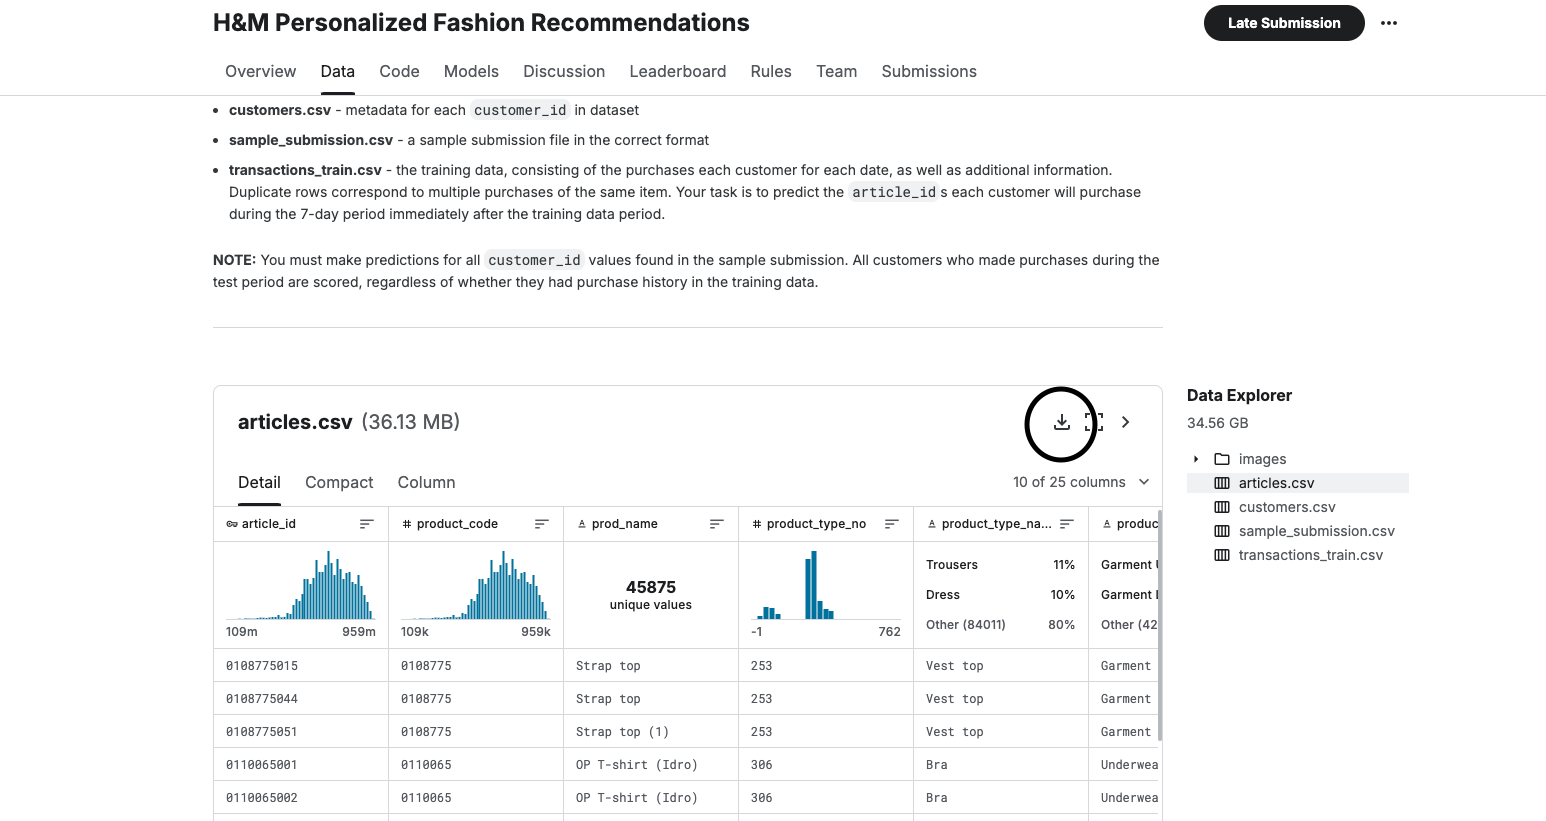




In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
# from google.colab import drive  # not needed locally
# from gensim.models import Word2Vec
from scipy.sparse import csr_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
# from google.colab import drive  # not needed locally
# from gensim.models import Word2Vec
from scipy.sparse import csr_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

## Step 2: Reading and Filtering Data

There are multiple ways you can read the dataset into a pandas dataframe.

With google colab,

1.   Upload the datasets into a folder in your google drive -> Mount your google drive into this session of google colab -> Directly read the dataframe from your google drive. The directory would be something like this. (Strongly advised)
`/content/drive/MyDrive/WHICHEVER_FOLDER_YOU_SAVED_IN/articles.csv"`

2.   Upload the datasets directly into the temp storage for this session (NOT ADVISED unless you plan to finish the assignment in 1 go). When the session is terminated, the datafiles will be removed from memory (meaning the next time you start a new session, you have to upload the large datafiles again).


As the original dataset is large, we will need to focus only on a subset of transactions that happened between '2019-09-20' to '2019-10-20'. The articles dataset will also be limited to the items that have been interacted during this period.

In [3]:
# Data is read from the local Kaggle download (kagglehub), no Google Drive needed
import kagglehub
articles_csv = kagglehub.competition_download('h-and-m-personalized-fashion-recommendations', path='articles.csv')
transactions_csv = kagglehub.competition_download('h-and-m-personalized-fashion-recommendations', path='transactions_train.csv')

df_a = pd.read_csv(articles_csv)
df_t = pd.read_csv(transactions_csv, usecols=['t_dat','customer_id','article_id','price','sales_channel_id'],
                   dtype={'article_id':'int32','price':'float32','sales_channel_id':'int8'})


In [4]:
""" Code is already provided, just run the cells"""
# DO NOT MODIFY ANY OF THE CODE FOUND IN THIS BLOCK. Just run this code block.
# Ensuring that 't_dat' is in date time format
df_t['t_dat'] = pd.to_datetime(df_t['t_dat'], format="%Y-%m-%d")

# Filtering transactions data to 1 month period
df_t = df_t[(df_t['t_dat'] >= '2019-09-20') & (df_t['t_dat'] <= '2019-10-20')]

# Filtering articles dataset
df_a = df_a[df_a['article_id'].isin(df_t['article_id'].unique())]

# Keeping columns required for assignment
columns_to_keep_a = ['article_id', 'prod_name', 'product_type_name', 'product_group_name',
                     'colour_group_name', 'perceived_colour_master_name', 'index_group_name',
                     'garment_group_name', 'detail_desc']

# Filter dataframe to retain only the required columns
df_a = df_a[columns_to_keep_a]

## Step 3: Data Description

Transactions Dataset (df_t)
1. t_dat: Date of transaction
2. customer_id: Unique identifier for customers
3. article_id: Unique identifer of item bought by the customer
4. price: Price of item (anonymised scale)
5. sales_channel_id: Channel the item bought the item from

Articles Dataset (df_a)
1. article_id: Unique identifer of item
2. prod_name: Name of product
3. product_type_name: Type of product
4. product_group_name: Group of product
5. colour_group_name: Colour of product
6. perceived_colour_master_name: General colour of product
7. index_group_name: Category of product
8. garment_group_name: Garment of product
9. detail_desc: Detailed description of products

In [5]:
df_t.head()

,t_dat,customer_id,article_id,price,sales_channel_id
16803901,2019-09-20,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,745014003,0.020322,2
16803902,2019-09-20,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,812484002,0.054220,2
16803903,2019-09-20,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,733098013,0.003373,2
16803904,2019-09-20,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,802842001,0.028797,2
16803905,2019-09-20,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,802842001,0.028797,2


In [6]:
df_a.head()

,article_id,prod_name,product_type_name,product_group_name,colour_group_name,perceived_colour_master_name,index_group_name,garment_group_name,detail_desc
0,108775015,Strap top,Vest top,Garment Upper body,Black,Black,Ladieswear,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,Strap top,Vest top,Garment Upper body,White,White,Ladieswear,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,OP T-shirt (Idro),Bra,Underwear,Black,Black,Ladieswear,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,OP T-shirt (Idro),Bra,Underwear,White,White,Ladieswear,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
5,110065011,OP T-shirt (Idro),Bra,Underwear,Light Beige,Beige,Ladieswear,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


## Step 4: Feature Engineering

Feature engineering involves creating new features from existing data to gain new insights and in some cases improve the explainability of machine learning models. Step 4 covers the process to engineer customer-based features and Step 5 covers the process to generate item-based features.

### Step 4.1: Customer-Based Features

**Customer-Based Features**

The Customer-based features that is created will be used for an unsupervised Machine Learning method - Clustering Analysis. This will allow us to split the large consumer base into small customer segments with similar habits and behaviours, allowing us to generate a variety of personalised recommendation strategies for each consumer group.

### Step 4.1.1: Average Time Between Purchases

Using the transactions dataset,a new feature is created to represent the average time difference between each purchase made by the customer. When creating this feature, a new customer dataframe is generated which will store all the customer information. The following instructions outlines how this process is done.

1. Sort df_t by `customer_id`, followed by `t_dat`. Set `inplace = True`, to ensure that the df_t follows this natural ordering.

2. Find the average time difference across all transactions by each customer. Label the new dataframe created as `df_c`.

3. Store this new average time difference feature as a new `time_diff` column in `df_c`.

In [7]:
# Sort df_t by `customer_id`, followed by `t_dat`
df_t.sort_values(by=['customer_id', 't_dat'], inplace=True)

# Group by customer_id, and find the difference between each transactions for each customer
df_t['time_diff'] = df_t.groupby('customer_id')['t_dat'].diff()

# Find the mean for each customer
df_c = df_t.groupby('customer_id')['time_diff'].mean().reset_index()
df_c

,customer_id,time_diff
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,0 days 00:00:00
1,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,8 days 00:00:00
2,000064249685c11552da43ef22a5030f35a147f723d5b0...,0 days 00:00:00
3,00009d946eec3ea54add5ba56d5210ea898def4b46c685...,3 days 14:24:00
4,0000c97821eb48d0e590fd309133f0a6c08f7750f64ccc...,0 days 00:00:00
...,...,...
264396,ffff4c4e8b57b633c1ddf8fbd53db16b962cf831baf9ed...,1 days 14:24:00
264397,ffff61677073258d461e043cc9ed4ed97be5617a920640...,NaT
264398,ffff7d65748db4d52e48b74c8f83ccb0029fc3bbafa511...,10 days 00:00:00
264399,ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab5...,0 days 00:00:00


### Step 4.1.2: Missing values in `time_diff`

In this `time_diff` feature, you will make 2 observations.

Observation 1. There are customers with 0 days 00:00:00 average time difference. These customers made multiple purchases on their first purchase and do not have any future purchases. It is not true to represent them as "frequent" buyers with 0 average time difference between their purchases.

Observation 2. There are NaN / NaT values within the column. This is because we cannot find the time difference for customers who have only made 1 item purchase in the dataset.

For the customers that fall in Observation 1, we will set their `time_diff` as np.nan. We will revisit this feature and handle its NaN values with mean imputation later on in step 4.3.

For the customers that fall in Observation 2, we will leave them be for now.



In [8]:
index_of_first_time_customers = df_c[df_c['time_diff'].dt.total_seconds() == 0].index
df_c.loc[index_of_first_time_customers, 'time_diff'] = np.nan
df_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264401 entries, 0 to 264400
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype          
---  ------       --------------   -----          
 0   customer_id  264401 non-null  object         
 1   time_diff    80074 non-null   timedelta64[ns]
dtypes: object(1), timedelta64[ns](1)
memory usage: 4.0+ MB


### Step 4.2: Average spending

Now, we will create a new feature to represent the average spending made by each customer. We label this feature as `average_spending` and likewise store it into the new `df_c` dataframe we have created in Step 4.1.

In [9]:
# Group by customer and find the mean total spending by each customer
customer_total_spent = df_t.groupby('customer_id')['price'].mean().reset_index()

# Assign it to df_c
df_c['average_spending'] = customer_total_spent['price']
df_c

,customer_id,time_diff,average_spending
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaT,0.054220
1,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,8 days 00:00:00,0.051890
2,000064249685c11552da43ef22a5030f35a147f723d5b0...,NaT,0.033881
3,00009d946eec3ea54add5ba56d5210ea898def4b46c685...,3 days 14:24:00,0.050831
4,0000c97821eb48d0e590fd309133f0a6c08f7750f64ccc...,NaT,0.019051
...,...,...,...
264396,ffff4c4e8b57b633c1ddf8fbd53db16b962cf831baf9ed...,1 days 14:24:00,0.019192
264397,ffff61677073258d461e043cc9ed4ed97be5617a920640...,NaT,0.025407
264398,ffff7d65748db4d52e48b74c8f83ccb0029fc3bbafa511...,10 days 00:00:00,0.033034
264399,ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab5...,NaT,0.016932


### Step 4.3: Handling missing values

Based on the 2 observations found earlier in Step 4.1.2, we will now address the NaN values found in `time_diff`. For these customers, let us assume that their `time_diff` will be the mean across all other customers who do not have NaN values. In other words, perform a Mean Imputation to fill in `time_diff` values for these customers. The following instructions outlines how this process is done.

1. Convert `time_diff` into hours format. Label this new column as `time_diff_hours`.

2. Find the average `time_diff_hours` across ALL customers who do not fall in any of the 2 observations stated above

3. For the customers that fall in the 2 observations stated above, fill in the `time_diff_hours` column with the mean value that was found above.


In [10]:
# Convert `time_diff` into hours format
df_c['time_diff_hours'] = df_c['time_diff'].dt.total_seconds() / 3600

# Find customers who made a transaction in a single visit only
first_time_customers = df_c['time_diff_hours'].isna()

# Find mean `time_diff_hours` for non first timer customers
mean_time_diff = df_c[~first_time_customers]['time_diff_hours'].mean()

print("Mean time_diff_hours:", mean_time_diff)

# Perform Mean Imputation NaN values
df_c['time_diff_hours'] = df_c['time_diff_hours'].fillna(mean_time_diff)
df_c.info()

Mean time_diff_hours: 69.92809477522648
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264401 entries, 0 to 264400
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   customer_id       264401 non-null  object         
 1   time_diff         80074 non-null   timedelta64[ns]
 2   average_spending  264401 non-null  float32        
 3   time_diff_hours   264401 non-null  float64        
dtypes: float32(1), float64(1), object(1), timedelta64[ns](1)
memory usage: 7.1+ MB


### Step 4.4: Customer Segment Analysis

Customer segmentation analysis using clustering techniques is crucial for enhancing the accuracy and relevance of the recommendations provided to users. By grouping users into distinct clusters based on their behaviors, businesses can analyse and target each segment with a valid recommendation strategy that cater to the specific behaviours of each customer.

In Step 4.4, the customer information features generated above is used to create a simple customer clustering.

<Axes: xlabel='average_spending', ylabel='time_diff_hours'>

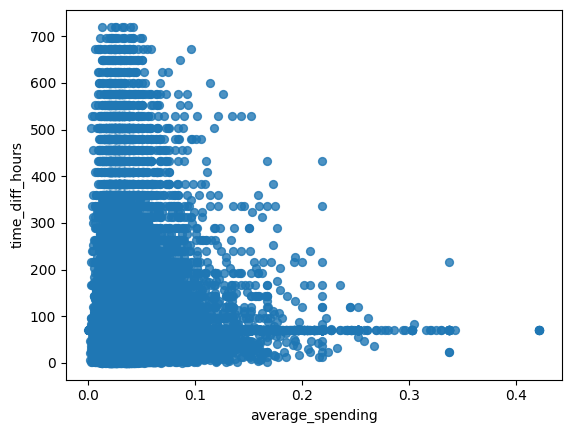

In [11]:
# We will be doing the customer clustering based on the 2 customer behaviour features that you have created in Step 4.1 and Step 4.2
cluster_features = df_c[['average_spending', 'time_diff_hours']]

# Create scatter plot on `time_diff_hours` against `average_spending` for visualisation
cluster_features.plot(kind='scatter', x='average_spending', y='time_diff_hours', s=32, alpha=.8)

In [12]:
# Initialise a standard scaler. As clustering relies on distance between each datapoint, we will need to ensure that
# all features are on the same scale. We use a standard scaler in this case.
scaler = StandardScaler()

# Fit and transform the numerical data
scaled_data = scaler.fit_transform(cluster_features[['average_spending', 'time_diff_hours']])

# Store the scaled data features into a dataframe
scaled_cluster_features = pd.DataFrame(scaled_data, columns=['average_spending', 'time_diff_hours'])

In [13]:
# Convert to numpy array to fit into KMeans algorithm
df_matrix = scaled_cluster_features.to_numpy()

# Choose optimal K using Elbow method
cost = []

# Loop across every possible cluster
for cluster in range(1, 10):
    kmeans = KMeans(n_clusters = cluster, random_state = 0)

    # Fit and predict each customer's cluster
    kmeans.fit_predict(df_matrix)

    # Store the cost, with the element's index being the cluster number
    cost.append(kmeans.inertia_)
    print('Cluster initiation: {}'.format(cluster))

Cluster initiation: 1


Cluster initiation: 2


Cluster initiation: 3


Cluster initiation: 4


Cluster initiation: 5


Cluster initiation: 6


Cluster initiation: 7


Cluster initiation: 8


Cluster initiation: 9


In [14]:
# Storing the cost of each cluster into a dataframe
df_cost = pd.DataFrame({'Cluster': range(1, 10), 'Cost':cost})

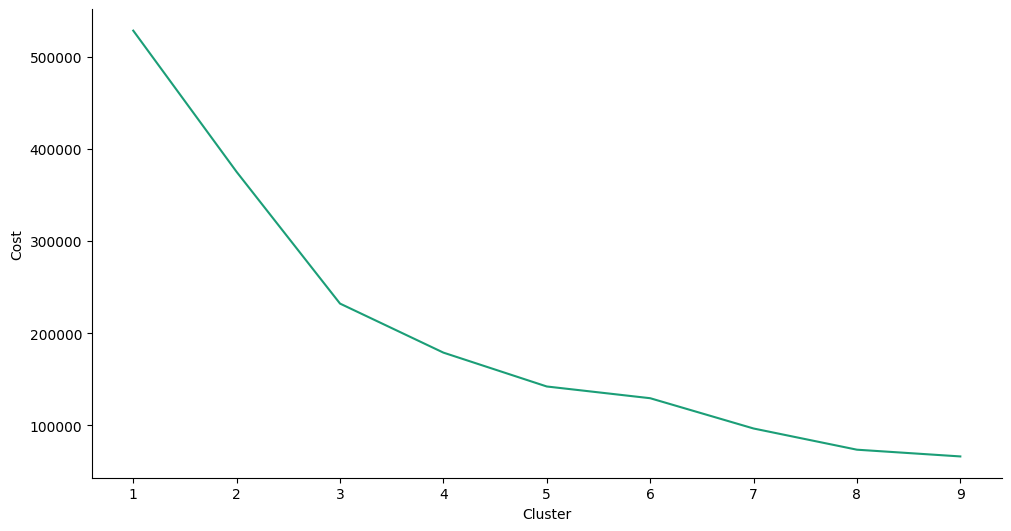

In [15]:
# Plots the cost with respect to the number of clusters
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  # x series
  xs = series['Cluster']
  # y series
  ys = series['Cost']
  # plot
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')

# Sort by ascending order of cluster
df_sorted = df_cost.sort_values('Cluster', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Cluster')
_ = plt.ylabel('Cost')

The elbow method is used to determine the optimal number of clusters in a clustering analysis because it provides a straightforward way to evaluate the balance between the complexity of the model (number of clusters) and the model's ability to explain the data variance (fit). In our case, we can see a "elbow-like" shape at cluster 3. Hence, we have determined that there are 3 customer segments from our dataset.

In [16]:
# Using the elbow method, the optimal number of clusters to choose is 3.
kmeans = KMeans(n_clusters = 3, random_state = 0)

# Fits the cluster_features and retrieve the Cluster Assignment predictions of each customer
kmeans.fit_predict(df_matrix)

array([0, 2, 0, ..., 2, 0, 0], dtype=int32)

In [17]:
cluster_features['cluster'] = kmeans.labels_

/var/folders/n0/06qt81n12nb7sf11vf0gz8240000gn/T/ipykernel_83439/3322027149.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster_features['cluster'] = kmeans.labels_


<Axes: xlabel='average_spending', ylabel='time_diff_hours'>

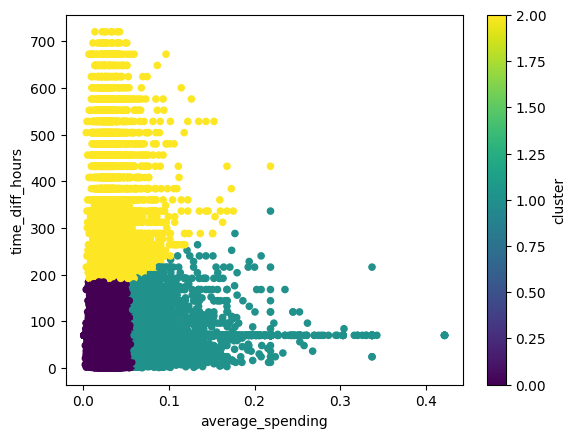

In [18]:
# Plots the scatterplot with cluster labelling to observe cluster behaviour
cluster_features.plot(kind='scatter', x='average_spending', y='time_diff_hours', c = 'cluster', colormap = 'viridis')

Observing the plot of the generated clusters, we can cluster customers into 3 segments. From there, we can implemented targetted business strategies to increase the sales of each cluster. For example:

---

**Yellow Cluster:** High Average Time Difference, Low Average Spending
Characteristics:

High Average Time Difference: These customers tend to wait longer between their purchases.
Low Average Spending: When they do make purchases, they spend relatively little.
Possible Insights:

Customer Behavior: This group might be less frequent buyers and more price-sensitive or cautious about their purchases.
Marketing Strategy: Targeting these customers might require focusing on incentives or promotions to encourage more frequent purchases or higher spending. Consider strategies like loyalty programs or personalized offers to boost their engagement.


---

**Purple Cluster:** Low Average Time Difference, Low Average Spending
Characteristics:

Low Average Time Difference: These customers make purchases relatively frequently.
Low Average Spending: Despite their frequent purchases, each transaction is relatively small.
Possible Insights:

Customer Behavior: This cluster includes customers who shop often but tend to spend modestly each time. They may be habitual buyers or might have a preference for cheaper or lower-value items.

Marketing Strategy: Consider strategies to increase their spending per purchase, such as upselling or cross-selling complementary products. You could also explore ways to increase their purchase frequency or overall engagement.

---

**Green Cluster:** Low Average Time Difference, High Average Spending
Characteristics:

Low Average Time Difference: These customers purchase regularly.
High Average Spending: Each purchase they make is relatively high in value.
Possible Insights:

Customer Behavior: This group represents high-value, frequent customers who are likely to be more loyal or have a high level of engagement with your products or services.

Marketing Strategy: Focus on retaining these valuable customers with premium offers, exclusive deals, or personalized attention. Consider implementing loyalty programs or high-touch customer service to maintain and enhance their engagement.





## Step 5: Item-Based Features

**Item Based Features**

The current item descriptions are in plain text format, which lacks the semantic structure needed for generating accurate item recommendations. Therefore, it's necessary to convert these descriptions into vectors to enable effective similarity searches between items.

### Step 5.1: Creating Item Embeddings

In order to generate item similarity recommendations, we will need to convert textual descriptions of each item into a vectorised format. This will allow us to use the item vectors to perform vector similarity searches and query for the most similar fashion products with respect to a reference product.

### Step 5.1.1: Missing `detail_desc`

You will notice that there are items where `detail_desc` is NaN (missing). As we still want to retain these items for similarity searches, we cannot leave them as blank fields. For these items, we will be constructing a basic `detail_desc` using existing features about the product. The columns used are ['product_type_name', 'colour_group_name', 'index_group_name', 'garment_group_name'].

For the items where `detail_desc` is NaN,

1. We will append each of the stated column's information together.
2. If any of the sub-columns (e.g. 'product_type_name') are NaN, we will use the fillna() function to fill it with a blank string ('') to prevent errors during concatenation.


In [19]:
desc_cols = ['product_type_name', 'colour_group_name', 'index_group_name', 'garment_group_name']

df_a.loc[df_a['detail_desc'].isna(), 'detail_desc'] = df_a.loc[df_a['detail_desc'].isna(), desc_cols].agg(' '.join, axis=1)

# Print df_a.info()
df_a.info()


<class 'pandas.core.frame.DataFrame'>
Index: 31042 entries, 0 to 93011
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   article_id                    31042 non-null  int64 
 1   prod_name                     31042 non-null  object
 2   product_type_name             31042 non-null  object
 3   product_group_name            31042 non-null  object
 4   colour_group_name             31042 non-null  object
 5   perceived_colour_master_name  31042 non-null  object
 6   index_group_name              31042 non-null  object
 7   garment_group_name            31042 non-null  object
 8   detail_desc                   31042 non-null  object
dtypes: int64(1), object(8)
memory usage: 2.4+ MB


### Step 5.1.2 TFIDF Vectoriser to generate item embeddings

Now that we have all the detailed description filled up, let us create item embeddings by fitting the detail descriptions into the TF-IDF Vectoriser model. We will store the embeddings as a result of the TFIDF-Vectoriser as `tfidf_scores`.

In [20]:
tfidf = TfidfVectorizer()

tfidf_scores = tfidf.fit_transform(df_a['detail_desc'])

### Row: The first dimension represents each document row in the df_a dataset.
### Column: The second dimension represents the number of unique terms across all descriptions.

## Step 6: Recommendation Strategies

### Introduction to the Strategies

Based on the insights provided, the model implements 2 Basic Recommendation Strategies.

1. Content Based Filtering

    Generating the Top K most similar items to the last purchased item.


2. Collaborative Filtering

    Generating recommendations from the Top K most similar customers in terms of purchase history.



### Step 6.1 Content-Based Filtering Recommendations

Using the item embeddings (`tfidf_scores`) that was generated, we can generate the Top K (default value = 10) most similar items to the `most recent purchased item` of the customer.


### Step 6.1.1: Most Recent Bought Item
 First, we will define the view_last_item_bought function to retrieve the `article_id` of the most recent bought item of a customer.

In [21]:
def view_last_item_bought(customer_id, df_t):
    last_bought_item = df_t[df_t['customer_id'] == customer_id]['article_id'].iloc[-1]
    return last_bought_item


### Step 6.1.2 Top K Most Similar Items

We now define the get_content_recommendation function to retrieve the top K most similar items as compared to the last bought item of the user. The following instructions outlines how this process is done.
    
1. Get the item embedding of the last bought item by the user. First, use the view_last_item_bought function to return the latest bought `article_id`. Next, find the embedding for this `article_id`. This will be your `query_embedding`.
    
2. Perform the cosine similarity function between your `query_embedding` vector and the entire item embedding matrix (`tfidf_scores`) to retrieve similarity scores between your query_embedding and all the other item embeddings in your matrix.
    
3. Set any item with a similarity score >= 0.95 to 0 as these will be considered items that are equivalent (perfectly similar) to the query item.

In [22]:
def get_content_recommendation(df_t, df_a, customer_id, tfidf_scores, k = 10):
    # Obtain the last bought item by a customer
    last_bought_item = view_last_item_bought(customer_id, df_t)

    # Get the original index of the last bought item in df_a
    # This returns a pandas Index object containing the original index value
    original_idx = df_a[df_a['article_id'] == last_bought_item].index[0]

    # Get the positional index (iloc) of this item in the current df_a dataframe
    # This positional index corresponds to the row index in tfidf_scores
    query_pos_idx = df_a.index.get_loc(original_idx)

    # Get query embedding of the last bought item
    query_embedding = tfidf_scores[query_pos_idx]

    # Perform cosine similarity with all the other item embeddings
    sim_vector = cosine_similarity(query_embedding, tfidf_scores).flatten()

    # Assign the equivalent items' scores to be 0 (prevent interacted items from being recommended again)
    sim_vector[sim_vector >= 0.95] = 0

    # Retrieve the top K results along side similarity scores
    top_k_similar_index = np.argsort(sim_vector)[::-1][:k]

    return df_a.iloc[top_k_similar_index]

In [23]:
# Example
get_content_recommendation(df_t, df_a, '00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657', tfidf_scores)

,article_id,prod_name,product_type_name,product_group_name,colour_group_name,perceived_colour_master_name,index_group_name,garment_group_name,detail_desc
24262,608769002,Bugg (2),Blazer,Garment Upper body,Black,Black,Ladieswear,Dressed,Jacket in woven fabric with notch lapels and a...
64220,740791001,Raven blazer,Blazer,Garment Upper body,Light Grey,Grey,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16017,568601030,Mariette Blazer,Blazer,Garment Upper body,Light Beige,Beige,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16018,568601031,Mariette,Blazer,Garment Upper body,Black,Black,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16005,568601008,Mariette,Blazer,Garment Upper body,Light Grey,Grey,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16020,568601034,Mariette,Blazer,Garment Upper body,Light Grey,Grey,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16004,568601007,Mariette Blazer,Blazer,Garment Upper body,Dark Blue,Blue,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16008,568601016,Mariette,Blazer,Garment Upper body,Dark Blue,Blue,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16019,568601033,Mariette,Blazer,Garment Upper body,Dark Green,Green,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...
16003,568601006,Mariette Blazer,Blazer,Garment Upper body,Black,Black,Ladieswear,Dressed,Fitted jacket in woven fabric with notch lapel...


### Step 6.2: User-Based Collaborative Filtering Recommendations

For this recommendation strategy, we will be performing User-based Collaborative Filtering where recommendations are generated from the `most popular` interactions by the `most similar` customers as compared to the query customer. We will consider only neighbours that have a similarity score (>= 0.6) which represents a high similarity in customer behaviour with respect to the query customer. Among these similar neighbours, We will then perform a majority voting on the most interacted items. The most popular items among the similar neighbours are recommended to the customer. `Take note, the recommended items have to be items that have not been interacted by the customer in the past.`


### Step 6.2.1 Creating the user-item interactions dataframe

We will create a dataframe that shows the number of purchases made by each user on each interacted item.

In [24]:
# Creates a dataframe that shows the number of purchases made by each user on each interacted item
user_item_interactions = df_t.groupby(['customer_id', 'article_id'])['price'].count().reset_index()

# Renaming the column to frequency
user_item_interactions = user_item_interactions.rename({'price' : 'frequency'}, axis = 1)

### Step 6.2.2: Preparing the similarity matrix

Using the LabelEncoder library from sklearn, we will run the fit_transform method to fit and transform the `customer_id` column and `article_id` column into indexes. We will create new columns for each of these indexes, `user_idx` and `item_idx` respectively in the `user_item_interactions` dataframe. These indexes generate the affinity (user-item) matrix where the indexes can be referenced back to the customer_id and article_id format easily.

Using the `user_item_interactions` dataframe we have defined in Step 6.2.1, we will create a sparse affinity (user-item) matrix using the scipy.sparse library. The rows represent the user encoded index, columns represent every article index in `df_a`. Each element is represented with a 1 if the user has purchased the item, and 0 if the user has not.

Now, wecall the sklearn's cosine_similarity function on the sparse affinity (user-item) matrix to find the most similar neighbouring customers (in terms of purchase behaviour) for each customer.

In [25]:
# Encode user and item IDs to numeric indices
user_encoder = LabelEncoder()
item_encoder = LabelEncoder()

user_item_interactions['user_idx'] = user_encoder.fit_transform(user_item_interactions['customer_id'])
user_item_interactions['item_idx'] = item_encoder.fit_transform(user_item_interactions['article_id'])

# Prepare data for CSR matrix
rows = user_item_interactions['user_idx']
cols = user_item_interactions['item_idx']
values = user_item_interactions['frequency']

### Note on the user-to-user similarity of Model 1 (Step 6.2)

I did not run the cell below on the full customer base on purpose. In the one-month window there are 264,401 unique customers, so the user-to-user cosine similarity would be a 264,401 x 264,401 matrix, which is around 559 GB in memory. This is simply too much: not even my Mac M4 Max could hold it, and it would be the same on Colab. This impossibility is itself one of the problems I discuss in Issue 4, so instead of forcing it I keep the cell as it was given and I demonstrate the point on a tractable subsample inside my answer for Issue 4.

In [ ]:
# Create CSR matrix
user_item_matrix = csr_matrix((values, (rows, cols)))

# Create user similarity matrix
user_similarity_matrix = cosine_similarity(user_item_matrix, dense_output=False)


### Step 6.3: Generating user-based collaborative filtering recommendations

We now define the get_collaborative_filtering_reccomendations function.
The get_collaborative_filtering_recommendations functions takes the arguments:
- user_similarity_matrix which has been defined in the previous step
- customer_id as the customer we want to generate recommendations for
- k = 10 which represents the top 10 recommendations generated
- sim_threshold = 0.6 which represents any customer that has a similarity score >= 0.6 is considered a similar customer and will be included in the majority voting process


The following instructions outlines how this process is done.

1. Encode the customer_id to retrieve the index of the customer you are generating recommendations for. Also, find out the list of article_ids that have already been interacted by the query customer.

2. Index `user_similarity_matrix` to find retrieve all the similarity scores between the queried user and all other customers

3. Filter `away` users who have perfect similarity scores (>= 0.95) as there are no new items to recommend to the query customer.

4. We will use a default threshold similarity of 0.6. Filter only neighbours that have similarity scores >= 0.6.

5. With the help of the defined `user_item_interactions` dataframe, find the most interacted items that were interacted by the most similar neighbours.


In [26]:
def get_collaborative_filtering_recommendations(user_similarity_matrix, customer_id, k=10, sim_threshold = 0.6):
    # Get the customer's list of interacted items.
    list_of_interacted_items = user_item_interactions[user_item_interactions['customer_id'] == customer_id]['article_id']

    # Get the index of the query customer within the affinity matrix
    customer_idx = user_encoder.transform([customer_id])

    # Retrieve all the similarity scores between the query user and all other customers
    sim_scores = user_similarity_matrix[customer_idx].toarray().flatten()

    # Filter away users who are exactly the same and above the similarity score threshold > 0.6
    filtered_users = np.argwhere((sim_scores < 1) & (sim_scores > sim_threshold))

    # Transform the filtered_user indexes back to customer_ids format
    filter_user_ids = user_encoder.inverse_transform(filtered_users)

    # Filter the user_item_interactions table to only include interactions by the most similar neighbours
    filtered_user_ids_interaction_table = user_item_interactions[user_item_interactions['customer_id'].isin(filter_user_ids)]

    # Filter away items that have already been interacted by the queried user
    filtered_user_ids_interaction_table = filtered_user_ids_interaction_table[~user_item_interactions['article_id'].isin(list_of_interacted_items)]

    # Do a majority voting on the most interacted items among these neighbours
    frequency_table = filtered_user_ids_interaction_table.groupby('article_id').sum()['frequency'].sort_values(ascending = False)

    # Retrieve top K results
    recommended_items = frequency_table.index[:k]

    return df_a[df_a['article_id'].isin(recommended_items)]

In [ ]:
# This function should work
items_to_recommend = get_collaborative_filtering_recommendations(user_similarity_matrix, '00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657')
items_to_recommend

# Model 2: Video Recommendation Model

The KuaiRec Recommendation Systems dataset is a large-scale dataset collected from KuaiShou, a popular short-video platform in China. It is designed for sequential and personalized recommendation research. The dataset contains user interaction sequences with short videos, including watch history, video features, user IDs, video IDs, and timestamps. KuaiRec is notable for its rich temporal dynamics, large user and item space, making it ideal for evaluating models in session-based and long-term user preference modeling tasks.

For more details: https://kuairec.com/

# Step 1: Reading, Filtering and Preprocessing the Data

Similar to Model 1, to download the datasets:

Login into Kaggle Account -> Access https://www.kaggle.com/datasets/arashnic/kuairec-recommendation-system-data-density-100 -> data. Download directly from there. (You only need big_matrix.csv and item_daily_features.csv, do not download the other files)


There are multiple ways you can read the dataset into a pandas dataframe.

Same as above, with google colab,

1. Upload the datasets into a folder in your google drive -> Mount your google drive into this session of google colab -> Directly read the dataframe from your google drive. The directory would be something like this. (Strongly advised) /content/drive/MyDrive/WHICHEVER_FOLDER_YOU_SAVED_IN/big_matrix.csv"

2. Upload the datasets directly into the temp storage for this session (NOT ADVISED unless you plan to finish the assignment in 1 go). When the session is terminated, the datafiles will be removed from memory (meaning the next time you start a new session, you have to upload the large datafiles again).


In [27]:
# Data is read from the local Kaggle download (kagglehub), no Google Drive needed
import kagglehub
kuairec_dir = kagglehub.dataset_download('arashnic/kuairec-recommendation-system-data-density-100') + '/KuaiRec 2.0/data'
item_daily_features = pd.read_csv(kuairec_dir + "/item_daily_features.csv")
big_matrix = pd.read_csv(kuairec_dir + "/big_matrix.csv")


In [28]:
big_matrix.head()

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,0,3649,13838,10867,2020-07-05 00:08:23.438,20200705,1.593879e+09,1.273397
1,0,9598,13665,10984,2020-07-05 00:13:41.297,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,2020-07-05 00:16:06.687,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,2020-07-05 00:20:26.792,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,2020-07-05 00:43:05.128,20200705,1.593881e+09,0.078000


In [29]:
item_daily_features.head()

,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,2,1,1,1,NaN,NaN,NaN,NaN


In [30]:
RANDOM_STATE = 4222
big_matrix_nonnull = big_matrix.dropna()
sampled_user_ids = big_matrix_nonnull['user_id'].sample(n=100, random_state = RANDOM_STATE)
big_matrix_filtered = big_matrix_nonnull[big_matrix_nonnull['user_id'].isin(sampled_user_ids)]

In [31]:
big_matrix_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 231518 entries, 278076 to 12396190
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   user_id         231518 non-null  int64  
 1   video_id        231518 non-null  int64  
 2   play_duration   231518 non-null  int64  
 3   video_duration  231518 non-null  int64  
 4   time            231518 non-null  object 
 5   date            231518 non-null  int64  
 6   timestamp       231518 non-null  float64
 7   watch_ratio     231518 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 15.9+ MB


### Step 2: Data Processing

The following steps were taken to process the data

1. Retain only essential columns needed for the assignment.
Retain the following columns: user_id, video_id, time, watch_ratio

2. Time Standardisation. Convert the time column into datetime format.

3. Outlier Removal. Filter away unrealistic watch ratios by clipping watch_ratio to (<= 5). It does not make sense for a user to watch the same video more than 5 times entirely. We use a threshold of 5 to filter away such unrealistic interactions. Print the shape of cleaned_small_matrix.

4. For the recommendations, we will need to represent a "like" and "dislike" interaction. We will now convert `watch_ratio` into a binary label with "like" interactions having a watch_ratio > 1.5 (i.e. watch_duration is 1.5 times of the video duration)

In [32]:
# Step 1: Retaining only columns we need
cleaned_big_matrix = big_matrix_filtered[['user_id', 'video_id', 'time', 'watch_ratio']]

# Step 2: Time Standardisation
cleaned_big_matrix['time'] = pd.to_datetime(cleaned_big_matrix['time']).dt.date

# Step 3: Removal Outlier Labels
print((cleaned_big_matrix['watch_ratio'] > 5).sum())

cleaned_big_matrix = cleaned_big_matrix[cleaned_big_matrix['watch_ratio'] <= 5]

# Step 4: Converting watch_ratio into a binary label
cleaned_big_matrix['label'] = (cleaned_big_matrix['watch_ratio'] > 1.5).astype(int)

1801


/var/folders/n0/06qt81n12nb7sf11vf0gz8240000gn/T/ipykernel_83439/3340798060.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_big_matrix['time'] = pd.to_datetime(cleaned_big_matrix['time']).dt.date


In real-world recommendation systems, label distributions are typically imbalanced, with far fewer positive interactions than negative ones. For example, a dataset may have only a 10% like ratio compared to 90% dislikes or ignored items. So this distribution of labels is rather realistic.

In [33]:
# Let us see the distribution of labels
cleaned_big_matrix['label'].value_counts()

label
0    198480
1     31237
Name: count, dtype: int64

Here we print some of the statistics of the interactions by users.

We will use the `average number of interactions per user per day` to decide the appropriate number of Top K recommendations we should be making for each user.

In [34]:
# Average Number of Interactions per user
print("Average Number of Interactions per user:", cleaned_big_matrix.groupby('user_id').size().mean())

# Total Number of Unique videos in the dataset
print("Total number of videos in the dataset:", cleaned_big_matrix['video_id'].nunique())

# Average Number of Interactions per user per day
print("Average Number of Interactions per user per day:", cleaned_big_matrix.groupby(['user_id', 'time']).size().mean())

Average Number of Interactions per user: 2297.17
Total number of videos in the dataset: 7652
Average Number of Interactions per user per day: 88.04791107704101


### Step 3: Splitting the Data

The big_matrix dataset contains all historical interactions for each user on Kuaishou. To facilitate robust model evaluation, the dataset is divided into two sections: Training and Test Set.

The Training set is used to train the model by learning patterns and relationships from user interactions.

The Test set is reserved for assessing the model's generalization ability on entirely new data, providing an unbiased evaluation of its real-world effectiveness.

Here we print the earliest date and latest dates in the dataset. We can see that the dataset consists of 2 months worth of interactions!

In [35]:
earliest_date = cleaned_big_matrix['time'].min()
latest_date = cleaned_big_matrix['time'].max()

print(f"Earliest date: {earliest_date}")
print(f"Latest date: {latest_date}")

Earliest date: 2020-07-05
Latest date: 2020-09-05


### Step 3.1: Performing the Time-based split

First, we need to perform a time - based split as the dataset contains the temporal aspects of user interactions. It is critical that we do not use a random train - test spilt as it will disrupt the natural sequence of events and potentially introduce data leakage.

A time - based split ensures that the model is trained on interactions that occured before a certain timestamp and evaluated on interactions after that point.

Next, we need to decide on an appropriate proportion for splitting the dataset into training and testing sets, given the need to balance sufficient training data for model learning with a representative test set for reliable evaluation.

We decide to go with an approximate 83% to 16% train - test spilt to ensure there are sufficient interactions for the evaluation. It is important that each user in the test set has more interactions as compared to the amount of Top K reccomendations that we are going to make.


In [36]:
train_data = cleaned_big_matrix[
    (cleaned_big_matrix['time'] >= pd.to_datetime('2020-07-04').date()) &
    (cleaned_big_matrix['time'] < pd.to_datetime('2020-08-30').date())
].copy()

test_data = cleaned_big_matrix[
    (cleaned_big_matrix['time'] >= pd.to_datetime('2020-08-30').date()) &
    (cleaned_big_matrix['time'] <= pd.to_datetime('2020-09-05').date())
].copy()

print(train_data.shape)
print(test_data.shape)

print("Ratio of train data:", train_data.shape[0] / cleaned_big_matrix.shape[0])
print("Ratio of test data:", test_data.shape[0] / cleaned_big_matrix.shape[0])

(191040, 5)
(38677, 5)
Ratio of train data: 0.8316319645476826
Ratio of test data: 0.1683680354523174


## Step 4: Building a Simple User Collaborative Filtering Model

We will be doing something similar to Model 1. Howecer, rather than using a fixed similarity threshold in Model 1, Step 6.2, now we will using a parameter `percentile` to determine the top percentile of similar users to based out recommendations from.

For instance a percentile of 90 would mean that we select the Top 10% most similar users, and a percentile of 95 would mean we select the top 5% most similar users.

### Step 4.1: Building the User Item Matrix

We will create a dataframe that shows the label (like = 1 / unlike = 0). Label this dataframe as ks_user_item_interactions.

In [37]:
ks_user_item_interactions = train_data.groupby(['user_id', 'video_id'])['label'].sum().reset_index()
ks_user_item_interactions

,user_id,video_id,label
0,150,10,0
1,150,80,0
2,150,86,0
3,150,122,0
4,150,124,0
...,...,...,...
161325,7091,10377,0
161326,7091,10403,0
161327,7091,10430,0
161328,7091,10435,1


### Step 4.2: Preparing the similarity matrix

We will prepare the similarity matrix now. The following instructions outlines how this process is done.


1. Using the LabelEncoder library from sklearn, run the fit_transform method to fit and transform the user_id column and video_id column into indexes. Create new columns for each of these indexes, user_idx and item_idx respectively in the ks_user_item_interactions dataframe. These indexes will be needed to generate the affinity (user-item) matrix where the indexes can be referenced back to the user_id and video_id format easily.

2. Using the ks_user_item_interactions dataframe we have defined earlier, create a sparse affinity (user-item) matrix using the scipy.sparse library. The rows represent the user encoded index, columns represent every video encoded index. Each element is represented with a 1 if the user has liked the item, and 0 if the user has not.

3. Call the sklearn's cosine_similarity function on the sparse affinity (user-item) matrix to find the most similar neighbouring customers for each customer.


In [38]:
# Encode user and item IDs to numeric indices
user_encoder = LabelEncoder()
item_encoder = LabelEncoder()

ks_user_item_interactions['user_idx'] = user_encoder.fit_transform(ks_user_item_interactions['user_id'])
ks_user_item_interactions['item_idx'] = item_encoder.fit_transform(ks_user_item_interactions['video_id'])

# Prepare data for CSR matrix
rows = ks_user_item_interactions['user_idx']
cols = ks_user_item_interactions['item_idx']
values = ks_user_item_interactions['label']

In [39]:
# Create CSR matrix
ks_user_item_matrix = csr_matrix((values, (rows, cols)))

print(ks_user_item_matrix.shape)

# Create user similarity matrix
ks_user_similarity_matrix = cosine_similarity(ks_user_item_matrix, dense_output=False)
ks_user_similarity_matrix

(100, 6726)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 9816 stored elements and shape (100, 100)>

### Step 4.3: Generating the collaborative filtering recommendations

We will now implement the get_collaborative_filtering_recommendations function. This function takes the arguments:

* user_similarity_matrix: precomputed user-user similarity matrix,

* user_id: the ID of the customer you want to generate recommendations for,

* k=50: the number of items to recommend (default top 50),

* percentile=90: the cutoff percentile to select the most similar users (default top 10% of most similar users).

The following instructions outlines how this process is done.

1. Retrieve the list of items (video_ids) already **liked** with by the query customer from the ks_user_item_interactions dataframe. (i.e. label == 1 and user_id == user_id in function argument)

2. Encode the user_id to get the index corresponding to the query customer in the user_similarity_matrix. Retrieve all similarity scores between the query user and all other users from the user_similarity_matrix that we have constructed.

3. Remove the self-similarity score of the query user (set it to 0) so that it does not affect the selection of similar users.

4. Compute the similarity threshold dynamically using the given percentile of similarity scores. Filter only those neighbours whose similarity scores exceed this threshold.

5. Convert the filtered user indices back to user_ids using the encoder. Use these user IDs to filter ks_user_item_interactions to include only interactions from the most similar neighbours. Hint: Use the inverse_transform function.

6. Exclude any items already liked by the query user from these interactions.

7. Perform majority voting on the remaining items to compute the frequency of liked interactions among these similar neighbours. Sort items in descending order of frequency to generate a ranked list.

8. Retrieve the list of top K videos from the sorted frequency table as the final recommendations.

In [40]:
def get_collaborative_filtering_recommendations(user_similarity_matrix, user_id, k=50, percentile=90):
    """
    Generate recommendations using collaborative filtering with a dynamic similarity threshold.

    Args:
        user_similarity_matrix: Precomputed user-user similarity matrix.
        user_id: The ID of the target user.
        k: Number of items to recommend (default=10).
        percentile: The cutoff percentile for most similar users (default=90 = top 10%).
    """

    # Get the user's list of liked videos
    list_of_interacted_items = ks_user_item_interactions[
        (ks_user_item_interactions['user_id'] == user_id) &
        (ks_user_item_interactions['label'] == 1)
    ]['video_id']

    # Get the index of the query customer within the affinity matrix
    user_idx = user_encoder.transform([user_id])

    # Retrieve all the similarity scores between the query user and all other customers
    sim_scores = user_similarity_matrix[user_idx].toarray().flatten()

    # Remove self-similarity (set it to 0 so it won’t affect percentile)
    sim_scores[user_idx] = 0.0

    # Compute threshold based on percentile
    sim_threshold = np.percentile(sim_scores, percentile)

    # Filter users above the similarity threshold
    filtered_users = np.argwhere(sim_scores > sim_threshold).flatten()

    # Transform the filtered_user indexes back to customer_ids format
    filter_user_ids = user_encoder.inverse_transform(filtered_users)

    # Filter the user_item_interactions table to only include interactions by the most similar neighbours
    filtered_user_ids_interaction_table = ks_user_item_interactions[
        ks_user_item_interactions['user_id'].isin(filter_user_ids)
    ]

    # Filter away items already interacted by the queried user
    filtered_user_ids_interaction_table = filtered_user_ids_interaction_table[
        ~filtered_user_ids_interaction_table['video_id'].isin(list_of_interacted_items)
    ]

    # Do a majority voting on the most interacted items among these neighbours, ensure sorted in descending order for ranking
    frequency_table = (
        filtered_user_ids_interaction_table.groupby('video_id')['label']
        .sum()
        .sort_values(ascending=False)
    )

    # Retrieve top K results
    recommended_items = frequency_table.index[:k]

    return list(recommended_items)

    return list(recommended_items)

### Step 4.3.1: Test the function for `test_user_id = 150`.

In [41]:
# Run this cell, this should work
test_user_id = 150
recommended_items = get_collaborative_filtering_recommendations(ks_user_similarity_matrix, test_user_id, k=50, percentile = 90)
print(recommended_items)
print(len(recommended_items))

[6001, 9731, 2125, 3722, 4367, 432, 217, 4266, 2343, 2178, 7274, 4411, 8718, 8504, 5952, 3723, 2052, 6846, 171, 2442, 8629, 4365, 2629, 416, 9795, 7521, 9850, 5412, 8739, 2723, 5915, 2696, 8732, 2588, 616, 8618, 8239, 8311, 3939, 3872, 918, 6829, 300, 961, 6787, 5560, 7511, 7113, 7271, 1017]
50


### Step 4.4: Generating recommendations for all the users

We will now generate recommendations for all users in the test dataset. The following instructions outlines how this process is done.


1. Initialize a dictionary, `recommended_items_per_user`, to store recommendations per user. The key = user_id, while the value = List of Top K Recommended Videos.

2. Get the ground truth of liked videos from test_data. Label this dictionary as `true_items_per_user`. The key = user_id, while the value = List of **liked** videos by the user, (i.e. label = 1)

3. Using the completed get_collaborative_filtering_recommendations **(set k = 500, percentile = 90)**, generate the Top K=500 recommendations for all users in the test set and store the recommendations in the `recommended_items_per_user` dictionary.

In [42]:
recommended_items_per_user = {}

# Filter "Liked" Items from test data
test_liked = test_data[test_data['label'] == 1]

# Retrieve the liked videos for each user
true_items_per_user = test_liked.groupby('user_id')['video_id'].apply(list).to_dict()

# For each user in the test dataset, generate up to 500 recommendations
for user_id in test_data['user_id'].unique():
    recommended_items_per_user[user_id] = get_collaborative_filtering_recommendations(ks_user_similarity_matrix, user_id, k=500, percentile = 90)

## Step 5: Evaluating the User Collaborative Filtering Model

Step 5 will evaluate our recommendations generated from the User Collaborative Filtering Model. We will be evaluating on 4 main metrics: Recall@K, NDCG@K, MAP@K and Hit Rate@K. These evaluation metrics are common metrics that are general to most recommendation systems. You are encouraged to explore other creative ways of evaluating your models for the project.

In [43]:
""" Code is given, just run the cells """
def precision_at_k(y_true, recommended_items, k):
    recommended_at_k = recommended_items[:k]
    hits = [1 if item in y_true else 0 for item in recommended_at_k]
    return np.mean(hits)

def recall_at_k(y_true, recommended_items, k):
    recommended_at_k = recommended_items[:k]
    hits = [1 if item in y_true else 0 for item in recommended_at_k]
    return np.sum(hits) / len(y_true) if len(y_true) > 0 else 0.0

def dcg_at_k(y_true, recommended_items, k):
    recommended_at_k = recommended_items[:k]
    gains = [1 if item in y_true else 0 for item in recommended_at_k]
    return np.sum([gain / np.log2(idx + 2) for idx, gain in enumerate(gains)])

def ndcg_at_k(y_true, recommended_items, k):
    ideal_items = list(y_true)
    ideal_dcg = dcg_at_k(y_true, ideal_items, k)
    if ideal_dcg == 0:
        return 0.0
    return dcg_at_k(y_true, recommended_items, k) / ideal_dcg

def average_precision_at_k(y_true, recommended_items, k):
    recommended_at_k = recommended_items[:k]
    hits = 0
    sum_precisions = 0.0
    for idx, item in enumerate(recommended_at_k):
        if item in y_true:
            hits += 1
            sum_precisions += hits / (idx + 1)
    return sum_precisions / min(len(y_true), k) if y_true else 0.0

def hit_rate_at_k(y_true, recommended_items, k):
    """Hit Rate@K: 1 if at least one relevant item is in top-K, else 0"""
    recommended_at_k = recommended_items[:k]
    return 1.0 if any(item in y_true for item in recommended_at_k) else 0.0

def evaluate_all_users(true_items_per_user, recommended_items_per_user, k=50):
    recall_list = []
    ndcg_list = []
    map_list = []
    hit_rate_list = []

    for user, true_items in true_items_per_user.items():
        recommended_items = recommended_items_per_user.get(user, [])

        recall_list.append(recall_at_k(true_items, recommended_items, k))
        ndcg_list.append(ndcg_at_k(true_items, recommended_items, k))
        map_list.append(average_precision_at_k(true_items, recommended_items, k))
        hit_rate_list.append(hit_rate_at_k(true_items, recommended_items, k))

    metrics = {
        'Recall@K': np.mean(recall_list),
        'nDCG@K': np.mean(ndcg_list),
        'MAP@K': np.mean(map_list),
        'HitRate@K': np.mean(hit_rate_list)
    }
    return metrics

In [44]:
# Test Run this code (This should work)
evaluate_all_users(true_items_per_user, recommended_items_per_user, k = 50)

{'Recall@K': 0.015738883722623012,
 'nDCG@K': 0.01436987404514274,
 'MAP@K': 0.0015908764899599085,
 'HitRate@K': 0.35106382978723405}

### Step 5.1: Choosing a K value

As all the evaluation metrics are strictly increasing with K, an increase in Top K recommendations would give better evaluation metrics. Now, we need to determine a suitable and realistic Top K number of reccomendations to make such that it does not completely bias your results or get perfect metrics.


For this model, we can use the number of test data interactions per user as a reference and choose k = 100 as a realistic value.

### Step 5.2: Optimising the Collaborative Filtering Model on the test set

Using our chosen value of k = 100, we can optimise the collaborative filtering model so that we can get the best evaluation metrics on the test set

In our collaborative filtering model, the percentile parameter is the only modifiable parameter which would affect our recommendation results. Hence, we aim to optimise it such that we get the best evaluation metrics on the test set.

Since we have provided 4 evaluation metrics, we want an equal weightage assigned to each evaluation metric to balance the optimisation across all evaluation metrics.

The following instructions outlines how this process is done.

1. Create multiple collaborative filtering models based on your chosen K values at different values of `percentile`. Test out at least 6 different values of `percentile`.

2. For each set of Top K (your chosen K) recommendations from different `percentile` values, compute the 4 evaluation metrics using the provided evaluate_all_users function.

3. Normalize the 4 evaluation metrics to a common scale to ensure comparability. The normalized metrics are then summed, with each metric given equal weight, resulting in a single aggregate score that reflects the overall performance of the recommendation system across multiple evaluation criteria.

4. Create a Line Plot of your scoring function with respect to different percentile values.

5. Print the 4 evaluation metrics of the best performing `percentile` value.

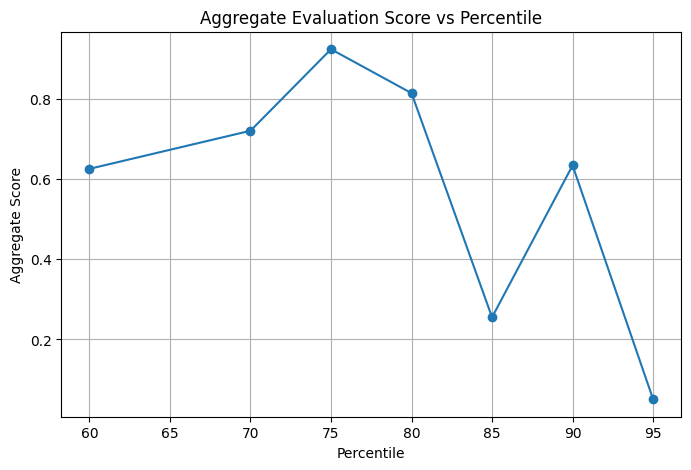

Best performing percentile: 75
Evaluation metrics at best percentile:
  Recall@K: 0.0276
  nDCG@K: 0.0186
  MAP@K: 0.0014
  HitRate@K: 0.5426


In [45]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Step 1: Create CF models for different percentile values
# -------------------------------
percentile_values = [60, 70, 75, 80, 85, 90, 95]  # Test at least 3 different percentiles
k = 100  # Top K recommendations
recommended_items_per_user_all = {}  # Store recommendations per percentile

# Filter "Liked" items from test data
test_liked = test_data[test_data['label'] == 1]
true_items_per_user_pct = test_liked.groupby('user_id')['video_id'].apply(list).to_dict()

for pct in percentile_values:
    recommended_items_per_user_pct = {}
    for user_id in test_data['user_id'].unique():
        recommended_items_per_user_pct[user_id] = get_collaborative_filtering_recommendations(
            ks_user_similarity_matrix,
            user_id,
            k=k,
            percentile=pct
        )
    recommended_items_per_user_all[pct] = recommended_items_per_user_pct

# -------------------------------
# Step 2: Compute evaluation metrics for each percentile
# -------------------------------
metrics_per_percentile = {}

for pct, recs in recommended_items_per_user_all.items():
    metrics_per_percentile[pct] = evaluate_all_users(true_items_per_user_pct, recs, k=k)

# -------------------------------
# Step 3: Normalize metrics and compute aggregate scores
# -------------------------------
metric_names = list(next(iter(metrics_per_percentile.values())).keys())
normalized_scores = {name: [] for name in metric_names}

# Normalize each metric across percentiles
for name in metric_names:
    values = [metrics_per_percentile[pct][name] for pct in percentile_values]
    min_val = np.min(values)
    max_val = np.max(values)
    norm_values = [(v - min_val) / (max_val - min_val) if max_val > min_val else 1.0 for v in values]
    normalized_scores[name] = norm_values

# Compute aggregate score per percentile (equal weight)
aggregate_scores = []
for i in range(len(percentile_values)):
    score = np.mean([normalized_scores[name][i] for name in metric_names])
    aggregate_scores.append(score)

# -------------------------------
# Step 4: Plot scoring function vs percentile
# -------------------------------
plt.figure(figsize=(8, 5))
plt.plot(percentile_values, aggregate_scores, marker='o', linestyle='-')
plt.xlabel('Percentile')
plt.ylabel('Aggregate Score')
plt.title('Aggregate Evaluation Score vs Percentile')
plt.grid(True)
plt.show()

# -------------------------------
# Step 5: Report best performing percentile
# -------------------------------
best_idx = np.argmax(aggregate_scores)
best_percentile = percentile_values[best_idx]
print(f"Best performing percentile: {best_percentile}")

print("Evaluation metrics at best percentile:")
for metric_name in metric_names:
    print(f"  {metric_name}: {metrics_per_percentile[best_percentile][metric_name]:.4f}")

# ANSWERS:

## Example of an Answer:


## Issue 1
**Model 1, Step 4.4**: Incomplete Feature Engineering in Customer Clustering

**Identified Issue**

In Model 1, customer clustering is performed using only two features: `average_spending` and `time_diff_hours`. This limited feature set assumes that customer behaviour can be adequately represented by spending level and inter-purchase timing alone.

While `time_diff_hours` captures the time between consecutive purchases for repeat customers, it does not capture other important behavioural dimensions such as overall purchase frequency, product preferences (`article_id`, `product_type_name`), sales channel usage (`sales_channel_id`), or temporal purchasing patterns. As a result, the constructed feature space may not reflect meaningful similarities or differences between customers.


**Substantive Justification**

Using an overly restricted feature set can lead to clusters that are statistically separable but behaviourally uninformative or misclassified.

> For example, consider two customers with similar average_spending and time_diff_hours:

>> Customer A makes frequent purchases of low-cost essentials through a single sales channel.

>> Customer B makes infrequent but regular purchases of high-variety discretionary items across multiple channels.

Despite having similar numerical values for the two clustering features, these customers represent fundamentally different behaviours and business value. Clustering them together obscures meaningful distinctions that are relevant for recommendation strategies, inventory planning, or targeted marketing.

As a result:

- Behaviourally distinct customers may be grouped into the same cluster.
- Downstream applications relying on these clusters may be biased or ineffective.
- The resulting clusters may lack clear business interpretability or actionability.
- This limitation therefore affects both the validity of the learned clusters and their usefulness for downstream decision-making.


**Proposed Solution**

I propose enriching the clustering feature space with additional behavioural features, followed by scaling and dimensionality reduction to manage complexity.

> Construct a richer set of customer-level behavioural features, apply standardisation, and use PCA to obtain a compact representation for clustering.

In addition to average_spending and time_diff_hours, suitable features may include:

- Purchase frequency (e.g. number of transactions per customer)
- Product diversity (e.g. number of unique product types purchased)
- Sales channel preference (e.g. dominant or most frequently used channel)
- Temporal patterns (e.g. variation in purchasing activity across months)

Standardising these features and applying PCA allows the model to capture dominant behavioural variation without over-emphasising any single feature due to scale differences.


**Solution Analysis**

The primary cost of this approach is increased modelling complexity.

- Feature enrichment requires additional preprocessing and aggregation, as well as domain judgement in defining meaningful behavioural indicators.
- Furthermore, dimensionality reduction via PCA reduces interpretability, since principal components are linear combinations of original features rather than directly observable behaviours.
- Additionally, clustering outcomes may become more sensitive to feature selection and preprocessing choices, which can affect stability if not carefully validated.

These costs are balanced by improved behavioural representation, making the resulting clusters more informative and actionable.

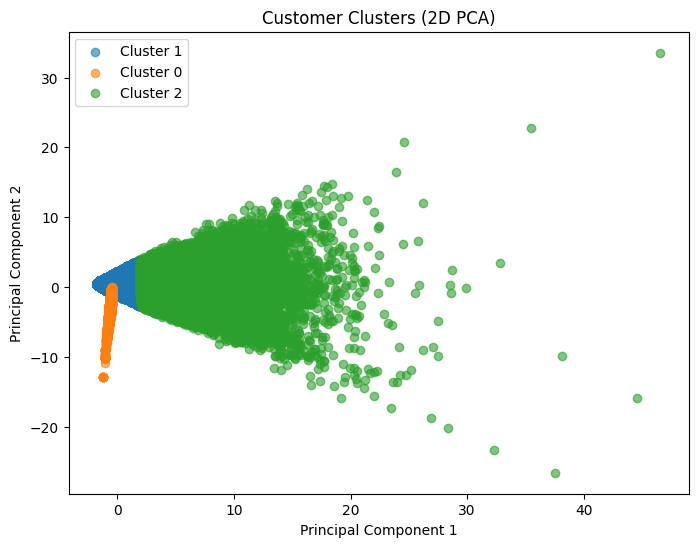

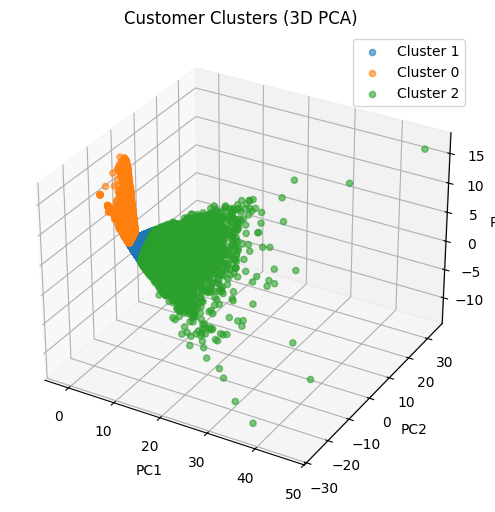

In [46]:
## Example of a solution cell

######################################
## MY SOLUTION for Issue 1
######################################
## MY SOLUTION for Issue 2
######################################
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.impute import SimpleImputer

import pandas as pd

#Feature Engineering
df = df_t.merge(df_a, on='article_id', how='left')

# Number of transactions (purchase frequency)
num_purchases = df.groupby('customer_id').size().rename('num_purchases')

# Customer tenure (days between first and last purchase)
first_purchase = pd.to_datetime(df.groupby('customer_id')['t_dat'].min())
last_purchase = pd.to_datetime(df.groupby('customer_id')['t_dat'].max())
tenure = (last_purchase - first_purchase).dt.days.rename('tenure')

# Number of unique product types purchased
product_diversity = df.groupby('customer_id')['product_type_name'].nunique().rename('product_diversity')

# Number of unique product groups purchased
num_product_groups = df.groupby('customer_id')['product_group_name'].nunique().rename('num_product_groups')

# Most frequently purchased product type
top_product_type = df.groupby('customer_id')['product_type_name'] \
                     .agg(lambda x: x.value_counts().idxmax()).rename('top_product_type')

# Sales channel preference (most frequently used channel per customer)
sales_channel_pref = df.groupby('customer_id')['sales_channel_id'] \
                        .agg(lambda x: x.value_counts().idxmax()).rename('sales_channel_pref')

# Temporal patterns (number of purchases per month to capture seasonality)
df['order_month'] = pd.to_datetime(df['t_dat']).dt.to_period('M')
temporal_pattern = df.groupby(['customer_id', 'order_month']).size().unstack(fill_value=0)
temporal_pattern.columns = [f'purchases_{str(col)}' for col in temporal_pattern.columns]

cluster_features = pd.concat([
    df_c[['average_spending', 'time_diff_hours']],  # numeric
    num_purchases,                                  # numeric
    tenure,                                         # numeric
    product_diversity,                              # numeric
    num_product_groups                              # numeric
], axis=1)
cluster_features_cat = pd.concat([top_product_type, sales_channel_pref], axis=1)    #categorical
cluster_features = cluster_features.join(temporal_pattern)

imputer = SimpleImputer(strategy='median')  # robust to outliers
cluster_features_imputed = imputer.fit_transform(cluster_features)


#PCA, Dimensionality Reduction
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_features_imputed)

pca = PCA(n_components=3)
reduced_data = pca.fit_transform(scaled_data)

kmeans = KMeans(n_clusters=3, n_init=20, random_state=42)
cluster_labels = kmeans.fit_predict(reduced_data)

pca_df = pd.DataFrame(reduced_data, columns=['PC1', 'PC2', 'PC3'])
pca_df['cluster'] = cluster_labels

# 2D Scatterplot (PC1 vs PC2)
plt.figure(figsize=(8,6))
for cluster in pca_df['cluster'].unique():
    subset = pca_df[pca_df['cluster'] == cluster]
    plt.scatter(subset['PC1'], subset['PC2'], label=f'Cluster {cluster}', alpha=0.6)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Clusters (2D PCA)')
plt.legend()
plt.show()

# 3D Scatterplot (PC1, PC2, PC3)
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
for cluster in pca_df['cluster'].unique():
    subset = pca_df[pca_df['cluster'] == cluster]
    ax.scatter(subset['PC1'], subset['PC2'], subset['PC3'], label=f'Cluster {cluster}', alpha=0.6)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('Customer Clusters (3D PCA)')
ax.legend()
plt.show()



---
# ============  MY ANSWERS  ============

# My submission - six substantive issues (A0350365H)

The following cells contain my own analysis of the data-preparation code. Every answer starts on a new Markdown cell and, for each issue, I indicate (1) the model and the step, (2) the problem and why it matters, (3) the alternative I propose, and (4) a short analysis of that alternative. Whenever it was feasible I supported the claim with evidence obtained from the real H&M and KuaiRec datasets; the shared setup below reads those datasets through kagglehub, exactly as the download instructions I used, and prepares the objects that the answer cells rely on.

In [47]:
# === Shared setup for my answers (A0350365H) ===
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import kagglehub

hm_transactions_file = kagglehub.competition_download('h-and-m-personalized-fashion-recommendations', path='transactions_train.csv')
hm_articles_file = kagglehub.competition_download('h-and-m-personalized-fashion-recommendations', path='articles.csv')
kuairec_folder = kagglehub.dataset_download('arashnic/kuairec-recommendation-system-data-density-100')
kuairec_big_matrix_file = kuairec_folder + '/KuaiRec 2.0/data/big_matrix.csv'

# ---- Model 1: rebuild the one-month customer table used by the previous analyst ----
one_month_chunks = []
for transaction_chunk in pd.read_csv(hm_transactions_file,
        usecols=['t_dat','customer_id','article_id','price'],
        dtype={'customer_id':'string','article_id':'int32','price':'float32'}, chunksize=3_000_000):
    one_month_chunks.append(transaction_chunk[(transaction_chunk['t_dat']>='2019-09-20') &
                                              (transaction_chunk['t_dat']<='2019-10-20')])
transactions_one_month = pd.concat(one_month_chunks, ignore_index=True); del one_month_chunks # 1-month data
transactions_one_month['t_dat'] = pd.to_datetime(transactions_one_month['t_dat'])
transactions_one_month.sort_values(['customer_id','t_dat'], inplace=True)
transactions_one_month['customer_purchase_time_difference'] = (
    transactions_one_month.groupby('customer_id')['t_dat'].diff())
customer_feature_table = (transactions_one_month
    .groupby('customer_id')['customer_purchase_time_difference'].mean().reset_index())

# ---- Model 1: item descriptions and their TF-IDF embeddings ----
articles_table = pd.read_csv(hm_articles_file)
articles_columns_kept = ['article_id','prod_name','product_type_name','product_group_name',
    'colour_group_name','perceived_colour_master_name','index_group_name','garment_group_name','detail_desc']
articles_table = articles_table[articles_table['article_id'].isin(
    transactions_one_month['article_id'].unique())][articles_columns_kept].reset_index(drop=True)
description_helper_columns = ['product_type_name','colour_group_name','index_group_name','garment_group_name']
missing_description_mask = articles_table['detail_desc'].isna()
articles_table.loc[missing_description_mask,'detail_desc'] = (
    articles_table.loc[missing_description_mask, description_helper_columns].agg(' '.join, axis=1))
item_tfidf_matrix = TfidfVectorizer().fit_transform(articles_table['detail_desc']) # item vectors

# ---- Model 2: the 100-user KuaiRec sample, kept both raw and processed ----
kuairec_all = pd.read_csv(kuairec_big_matrix_file, usecols=['user_id','video_id','time','watch_ratio']).dropna()
sampled_one_hundred_users = pd.Series(kuairec_all['user_id'].unique()).sample(n=100, random_state=4222)
kuairec_sample_raw = kuairec_all[kuairec_all['user_id'].isin(sampled_one_hundred_users)].copy()
kuairec_sample_raw['time'] = pd.to_datetime(kuairec_sample_raw['time']).dt.date
kuairec_interactions = kuairec_sample_raw[kuairec_sample_raw['watch_ratio'] <= 5].copy() # drop >5 outliers
kuairec_interactions['label'] = (kuairec_interactions['watch_ratio'] > 1.5).astype(int) # binary label
del kuairec_all

def kuairec_time_slice(frame, start_date, end_date):
    return frame[(frame['time'] >= pd.to_datetime(start_date).date()) &
                 (frame['time'] <  pd.to_datetime(end_date).date())].copy()
kuairec_train = kuairec_time_slice(kuairec_interactions, '2020-07-04', '2020-08-30')
kuairec_test  = kuairec_interactions[(kuairec_interactions['time'] >= pd.to_datetime('2020-08-30').date()) &
                                     (kuairec_interactions['time'] <= pd.to_datetime('2020-09-05').date())].copy()

def build_user_similarity(train_frame):
    interaction_frame = train_frame.groupby(['user_id','video_id'])['label'].sum().reset_index()
    user_label_encoder, item_label_encoder = LabelEncoder(), LabelEncoder()
    interaction_frame['user_index'] = user_label_encoder.fit_transform(interaction_frame['user_id'])
    interaction_frame['item_index'] = item_label_encoder.fit_transform(interaction_frame['video_id'])
    sparse_user_item = csr_matrix((interaction_frame['label'],
                                   (interaction_frame['user_index'], interaction_frame['item_index'])))
    similarity = cosine_similarity(sparse_user_item, dense_output=False)
    return interaction_frame, user_label_encoder, similarity

def collaborative_recommendations(interaction_frame, user_label_encoder, similarity,
                                  target_user, k=100, percentile=90):
    liked_videos = interaction_frame[(interaction_frame['user_id']==target_user) &
                                     (interaction_frame['label']==1)]['video_id']
    if target_user not in user_label_encoder.classes_:
        return []
    target_index = user_label_encoder.transform([target_user])[0]
    similarity_scores = similarity[target_index].toarray().flatten(); similarity_scores[target_index] = 0
    neighbour_threshold = np.percentile(similarity_scores, percentile)
    neighbour_users = user_label_encoder.inverse_transform(
        np.argwhere(similarity_scores > neighbour_threshold).flatten())
    neighbour_interactions = interaction_frame[interaction_frame['user_id'].isin(neighbour_users)]
    neighbour_interactions = neighbour_interactions[~neighbour_interactions['video_id'].isin(liked_videos)]
    ranked_videos = neighbour_interactions.groupby('video_id')['label'].sum().sort_values(ascending=False)
    return list(ranked_videos.index[:k])

def recall_at_k(relevant_items, recommended_items, k=100):
    if not len(relevant_items):
        return 0.0
    return sum(1 for v in recommended_items[:k] if v in relevant_items) / len(relevant_items)

print('Setup ready. One-month transactions:', len(transactions_one_month),
      '| customers:', customer_feature_table.shape[0],
      '| KuaiRec sample rows:', len(kuairec_interactions))

Setup ready. One-month transactions: 1313295 | customers: 264401 | KuaiRec sample rows: 176899


## Issue 1
**Model 1, Step 4.1.2 and Step 4.3**: A time difference of zero is treated as missing and then imputed with the mean

**Identified Issue**

According to what the professor showed us in the Representation slides (Topic 2), the way we treat the missing values changes what the model can learn, so I looked at these two steps carefully. In Step 4.1.2 the customers whose `time_diff` is zero are changed to `NaN`, and in Step 4.3 all the missing values are filled with the global mean.

**Substantive Justification**

The reason this matters is that a zero is not really a missing value. It belongs to the customers who buy many times in the same day, so they are actually the most frequent ones, and by turning them into NaN we lose that signal. Furthermore, the customers with only one purchase do not have a time between purchases at all, so filling them with the mean gives them a behaviour that is not real. For that reason the feature stops being useful, and as the numbers below show, almost seven of every ten customers finish with a value that was erased or invented. Since Step 4.4 builds the clusters with this same feature, the segmentation is affected.

**Proposed Solution**

I would not change the zero to NaN, because it is a real value that means high frequency. For the customers with a single purchase I would keep them apart with a flag `is_one_time_buyer` instead of giving them a fake mean, and if I still need a number I would use the median, that is less affected by the very frequent customers.

**Solution Analysis**

- I keep the frequency signal instead of deleting it, and I do not mix two very different groups inside the same number.
- The cost is that I add one more column, and the value for the one-time buyers is still a decision, so the flag is better than any imputed number.
- Even so, for me it is more honest than saying that every customer has an average time between purchases.

In [48]:
# Issue 1 (Model 1, Steps 4.1.2 and 4.3) — evidence
customers_flagged_same_day = (customer_feature_table['customer_purchase_time_difference'].dt.total_seconds() == 0).sum() # same-day buyers
customers_single_purchase  = customer_feature_table['customer_purchase_time_difference'].isna().sum() # one-time buyers
total_customers = len(customer_feature_table)
customers_with_feature_distorted = customers_flagged_same_day + customers_single_purchase
print(f"Same-day repeat customers turned into NaN : {customers_flagged_same_day} ({100*customers_flagged_same_day/total_customers:.1f}%)")
print(f"One-time buyers (no interval by definition): {customers_single_purchase} ({100*customers_single_purchase/total_customers:.1f}%)")
print(f"Customers whose time feature is erased or fabricated: {customers_with_feature_distorted} ({100*customers_with_feature_distorted/total_customers:.1f}%)")

# variance collapse produced by the mean imputation
time_difference_in_hours = customer_feature_table['customer_purchase_time_difference'].dt.total_seconds() / 3600
genuine_values_only = time_difference_in_hours[time_difference_in_hours > 0] # real gaps only
mean_gap_repeat_customers = genuine_values_only.mean()
time_feature_after_original_imputation = time_difference_in_hours.where(time_difference_in_hours > 0).fillna(mean_gap_repeat_customers) # original impute
print(f"\nStd of the genuine inter-purchase gaps : {genuine_values_only.std():.2f} hours")
print(f"Std after the original zero->NaN->mean step : {time_feature_after_original_imputation.std():.2f} hours  (variance is largely collapsed)")

Same-day repeat customers turned into NaN : 130311 (49.3%)
One-time buyers (no interval by definition): 54016 (20.4%)
Customers whose time feature is erased or fabricated: 184327 (69.7%)

Std of the genuine inter-purchase gaps      : 84.52 hours
Std after the original zero->NaN->mean step  : 46.51 hours  (variance is largely collapsed)


## Issue 2
**Model 1, Step 4.2**: `average_spending` is the mean item price, not the customer spending

**Identified Issue**

In her Representation slides (Topic 2) the professor defined a feature, following Bishop, as a measurable property that should represent the phenomenon we care about. With that definition in mind I noticed that `average_spending` does not represent spending. It is created with `groupby('customer_id')['price'].mean()`, so it is the average price of the transaction lines.

**Substantive Justification**

The reason this matters is that the mean price is the price tier of what the customer buys, and not how much money the customer spends nor how often. For example, a customer with fifty cheap purchases and a customer with only one cheap purchase get the same value, even though one spends much more than the other. I confirmed on the real data that this feature barely correlates with the true expenditure. Since it feeds the segmentation and it is supposed to represent customer value, the segments become misleading.

**Proposed Solution**

I would separate the ideas that are being mixed: a `total_expenditure` with the sum of `price` for the volume, a `number_of_purchases` for the frequency, and, if the price tier is still useful, keep the mean but with the correct name `average_item_price`.

**Solution Analysis**

- This tells apart spending from price tier and gives the clustering a real notion of value.
- The cost is that `total_expenditure` over one month depends on how long each customer was active, so it should be documented or normalised by the active days.
- Even so, it is much closer to the real meaning than the mean price.

In [49]:
# Issue 2 (Model 1, Step 4.2) — evidence
customer_spending_table = transactions_one_month.groupby('customer_id').agg(
    average_item_price=('price', 'mean'), # price tier
    total_expenditure=('price', 'sum'), # real spend
    number_of_purchases=('price', 'count')).reset_index() # frequency
correlation_price_vs_true_spend = customer_spending_table['average_item_price'].corr(customer_spending_table['total_expenditure']) # weak link
print(f"corr(average_item_price , total_expenditure) = {correlation_price_vs_true_spend:.3f}  (low => they measure different things)")
most_frequent_customer = customer_spending_table.sort_values('number_of_purchases', ascending=False).iloc[0]
print("\nMost frequent customer in the window:")
print(f"  purchases = {int(most_frequent_customer['number_of_purchases'])}")
print(f"  average_item_price = {most_frequent_customer['average_item_price']:.3f}  <- what the original feature stores")
print(f"  total_expenditure = {most_frequent_customer['total_expenditure']:.3f}  <- what 'spending' should be")

corr(average_item_price , total_expenditure) = 0.267  (low => they measure different things)

Most frequent customer in the window:
  purchases        = 179
  average_item_price = 0.016  <- what the original feature stores
  total_expenditure  = 2.938  <- what 'spending' should be


## Issue 3
**Model 1, Step 6.1.2**: The content recommendation uses only the last item and a `similarity >= 0.95` trick

**Identified Issue**

As the professor showed us in her Topic 4 slides on the Basic Recommendation Model, content-based filtering recommends the items with the highest similarity with the items the user has interacted with, in plural, using the cosine over the TF-IDF vectors. Nevertheless, in this step the function `view_last_item_bought` returns only the last purchased article, so the whole recommendation is built from a single item, and the line `sim_vector[sim_vector >= 0.95] = 0` is used to remove that item.

**Substantive Justification**

The reason this matters is that the last purchase can be atypical, a gift or an impulse, so building everything from it is fragile and it ignores the rest of the history. Furthermore, the `0.95` trick is indirect, because it also deletes near-duplicate articles without wanting to, and it does not exclude the other items the customer already bought. For that reason I repeated the comparison over fifty customers with a diverse history, and on average the two lists of recommendations almost do not agree, which shows that the last item is not representative.

**Proposed Solution**

I would represent the customer with the average of the TF-IDF vectors of the whole history, that is a profile, and I would exclude the items already bought by their id, not by a similarity threshold.

**Solution Analysis**

- Using all the history gives recomendations that are more stable and representative, and excluding by id is clear.
- The cost is that the average blurs a customer with several different interests, because the profile falls in the middle.
- A more advanced version would group the customer items into interests before recommending, but that is more work.

In [50]:
# Issue 3 (Model 1, Step 6.1.2) — evidence over many customers
customer_history_items = transactions_one_month.groupby('customer_id')['article_id'].apply(list)
customers_with_diverse_history = customer_history_items[
    customer_history_items.apply(lambda items: len(set(items)) >= 5)].index[:50] # 50 customers

def top_ten_similar_positions(query_vector, positions_to_exclude):
    similarity_scores = cosine_similarity(query_vector, item_tfidf_matrix).flatten()
    for position in positions_to_exclude:
        similarity_scores[position] = -1
    return set(np.argsort(similarity_scores)[::-1][:10])

overlap_last_item_vs_profile = []
for customer_identifier in customers_with_diverse_history:
    purchased_articles_in_order = list(dict.fromkeys(
        transactions_one_month[transactions_one_month['customer_id'] == customer_identifier]
        .sort_values('t_dat')['article_id']))
    purchased_row_positions = [articles_table.index[articles_table['article_id'] == a][0]
                               for a in purchased_articles_in_order if (articles_table['article_id'] == a).any()]
    if len(purchased_row_positions) < 2:
        continue
    recommendations_from_last_item = top_ten_similar_positions(item_tfidf_matrix[purchased_row_positions[-1]], [purchased_row_positions[-1]]) # last item only
    customer_profile_vector = np.asarray(item_tfidf_matrix[purchased_row_positions].mean(axis=0)) # full profile
    recommendations_from_full_profile = top_ten_similar_positions(customer_profile_vector, purchased_row_positions)
    overlap_last_item_vs_profile.append(len(recommendations_from_last_item & recommendations_from_full_profile)) # compare top-10

overlap_last_item_vs_profile = np.array(overlap_last_item_vs_profile)
print(f"Customers analysed : {len(overlap_last_item_vs_profile)}")
print(f"Mean top-10 overlap (last item only vs full profile) : {overlap_last_item_vs_profile.mean():.1f} / 10")
print(f"Customers where the two lists share 2 items or fewer : {100*(overlap_last_item_vs_profile <= 2).mean():.0f}%")
print("=> on average the last-item recommender and the full-history one almost do not agree")

Customers analysed                                   : 50
Mean top-10 overlap (last item only vs full profile) : 1.0 / 10
Customers where the two lists share 2 items or fewer : 82%
=> on average the last-item recommender and the full-history one almost do not agree


## Issue 4
**Model 1, Steps 5.1.2 and 6.2**: Cosine similarity over raw counts on a very sparse one-month matrix

**Identified Issue**

In her Representation slides (Topic 2) the professor explained that the cosine similarity ignores the zero-zero matches and that it is useful for sparse data, and in Topic 4 she builds the user similarity with the cosine in the same way. In this step the user-item matrix is filled with the raw purchase counts and the cosine is computed directly on them, over only one month of data.

**Substantive Justification**

The reason this matters has two parts. First, with raw counts the customers who buy the most look similar to almost everyone, and I confirmed on the data a positive correlation between how much a customer buys and how similar the model thinks they are to the rest, so the neighbours are biased to the heavy buyers. Second, because it is only one month the matrix is very sparse, with a density of about one hundredth of a percent, and a fifth of the customers bought only once, so most pairs share nothing and their similarity is meaningless. This same sparsity over all the customers is also why the full similarity matrix does not fit in memory, as I explain in the note above.

**Proposed Solution**

I would weight or binarise the interaction instead of using the raw counts, for example a binary implicit-feedback matrix or a TF-IDF weighting that lowers the weight of the very popular items, and I would document the effect of the one-month window, making it wider if the business allows it.

**Solution Analysis**

- Binarising lowers the dominance of the heavy buyers and makes the similarity more stable on sparse data.
- The cost is that a binary matrix loses the intensity of the interaction, and a wider window reduces the sparsity but can mix older preferences.
- For that reason, if I widen the window I would say it clearly instead of assuming it.

In [51]:
# Issue 4 (Model 1, Steps 5.1.2 and 6.2) — evidence
number_of_customers     = transactions_one_month['customer_id'].nunique()
number_of_articles      = transactions_one_month['article_id'].nunique()
number_of_nonzero_pairs = transactions_one_month.groupby(['customer_id','article_id']).ngroups # filled cells
user_item_matrix_density = 100 * number_of_nonzero_pairs / (number_of_customers * number_of_articles) # how sparse
print(f"user-item matrix: {number_of_customers} x {number_of_articles}; non-zero cells = {number_of_nonzero_pairs}")
print(f"density = {user_item_matrix_density:.4f}%  (extremely sparse)")
purchase_counts_per_customer = transactions_one_month.groupby('customer_id').size()
print(f"customers with a single purchase = {100*(purchase_counts_per_customer == 1).mean():.1f}%  (almost no overlap for CF)")

# raw counts let heavy buyers look similar to everyone so then i checked on a tractable 3000-customer subsample
subsample_customer_ids = pd.Series(transactions_one_month['customer_id'].unique()).sample(3000, random_state=4222)
subsample_transactions = transactions_one_month[transactions_one_month['customer_id'].isin(subsample_customer_ids)]
subsample_pairs = subsample_transactions.groupby(['customer_id','article_id']).size().reset_index(name='purchase_count')
subsample_user_encoder, subsample_item_encoder = LabelEncoder(), LabelEncoder()
subsample_pairs['user_index'] = subsample_user_encoder.fit_transform(subsample_pairs['customer_id'])
subsample_pairs['item_index'] = subsample_item_encoder.fit_transform(subsample_pairs['article_id'])
subsample_matrix = csr_matrix((subsample_pairs['purchase_count'],
                               (subsample_pairs['user_index'], subsample_pairs['item_index'])))
subsample_similarity = cosine_similarity(subsample_matrix, dense_output=False) # user sims
average_similarity_to_others = (np.asarray(subsample_similarity.sum(axis=1)).flatten() - 1) / (subsample_similarity.shape[0] - 1)
purchase_volume_per_user = subsample_pairs.groupby('user_index')['purchase_count'].sum().reindex(range(subsample_similarity.shape[0])).fillna(0).values
correlation_volume_vs_similarity = np.corrcoef(purchase_volume_per_user, average_similarity_to_others)[0, 1] # volume vs sim
print(f"\nOn a 3000-customer subsample: corr(purchase volume , average similarity to others) = {correlation_volume_vs_similarity:.3f}")
print("=> with raw counts, the more a customer buys the more 'similar' they look to everyone (heavy-buyer dominance)")

user-item matrix: 264401 x 31042; non-zero cells = 1151338
density = 0.0140%  (extremely sparse)
customers with a single purchase = 20.4%  (almost no overlap for CF)



On a 3000-customer subsample: corr(purchase volume , average similarity to others) = 0.371
=> with raw counts, the more a customer buys the more 'similar' they look to everyone (heavy-buyer dominance)


## Issue 5
**Model 2, Step 2**: An arbitrary `watch_ratio > 1.5` label and deleting `watch_ratio > 5`

**Identified Issue**

According to the professor's Representation slides (Topic 2), a good feature should not have extreme outliers, and to handle them she showed capping the value, not deleting the row. In this step the rows with `watch_ratio > 5` are deleted, and the label is defined as `watch_ratio > 1.5`.

**Substantive Justification**

The reason this matters is that the rows with `watch_ratio > 5` are exactly the ones with the highest engagement, the videos that were watched again or looped, which is a strong positive signal, so deleting them does not make sense if later we define the positives by engagement. Furthermore, the threshold `1.5` is not justified, and as the evidence shows, moving it between 1.0 and 2.0 changes the amount of positives a lot, so the target depends on an arbitrary number. In addition, connecting it with the Evaluation slides (Topic 4), a big part of the videos liked in the test never appear in train, so the recall already has a ceiling below one.

**Proposed Solution**

Instead of deleting `watch_ratio > 5` I would cap it, that is winsorise, so the rows with high engagement stay but the extreme values do not distort the scale, and for the threshold I would justify it from the distribution or report the sensitivity to several thresholds, keeping `watch_ratio` continuous or in a few levels if possible.

**Solution Analysis**

- Capping keeps the most engaged interactions, and a justified threshold makes the target reproducible.
- The cost is that a continuous or multi-level target makes the current binary matrix more complex, and capping still compresses the tail.
- Even so, it does not aligns the target to a cut-off that nobody examined.

In [52]:
# Issue 5 (Model 2, Step 2) — evidence
rows_before_outlier_removal   = len(kuairec_sample_raw)
rows_removed_high_engagement  = (kuairec_sample_raw['watch_ratio'] > 5).sum() # high engagement
print(f"Interactions removed by watch_ratio>5 (highest engagement): {rows_removed_high_engagement} ({100*rows_removed_high_engagement/rows_before_outlier_removal:.2f}%)")
watch_ratio_kept = kuairec_sample_raw[kuairec_sample_raw['watch_ratio'] <= 5]['watch_ratio']
print("\nPositive-label ratio for different thresholds (the definition of 'like' moves a lot):")
for candidate_threshold in [1.0, 1.2, 1.5, 2.0]:
    positive_label_ratio = (watch_ratio_kept > candidate_threshold).mean() # label balance
    marker = "   <- the one used" if candidate_threshold == 1.5 else ""
    print(f"  threshold {candidate_threshold}: positives = {100*positive_label_ratio:.1f}%{marker}")

# and the same window used for evaluation cannot even reach the videos it should
videos_seen_in_train   = set(kuairec_train['video_id'])
liked_videos_in_test   = kuairec_test[kuairec_test['label'] == 1]
reachable_fraction     = liked_videos_in_test['video_id'].isin(videos_seen_in_train).mean() # cold-start ceiling
print(f"\nTest-liked videos that ever appear in train (reachable at all): {100*reachable_fraction:.1f}%  -> a recall ceiling below 1")

Interactions removed by watch_ratio>5 (highest engagement): 1542 (0.86%)

Positive-label ratio for different thresholds (the definition of 'like' moves a lot):
  threshold 1.0: positives = 34.5%
  threshold 1.2: positives = 24.3%
  threshold 1.5: positives = 14.8%   <- the one used
  threshold 2.0: positives = 6.5%

Test-liked videos that ever appear in train (reachable at all): 63.7%  -> a recall ceiling below 1


## Issue 6
**Model 2, Step 5.2**: The percentile is chosen on the test set, which is data leakage

**Identified Issue**

This is the issue I was most sure about, because in her Optimization slides (Topic 3) the professor was very clear that we must never tune a decision by looking at the test set, and she showed the correct workflow with a Training, a Validation and a Test set, where the validation is the one we use to tweak the model. Nevertheless, Step 5.2 tries several percentile values, evaluates each one on the test set, and reports the percentile that gives the best metrics on that same test set.

**Substantive Justification**

The reason this matters is that choosing the percentile on the test makes the reported number too optimistic and it will not generalise, because the percentile was picked for that particular test. Furthermore, connecting it with the Evaluation slides (Topic 4), Step 5.1 assumes that every metric grows with K and then recommends five hundred items, which raises the recall and the hit-rate but is not realistic, because the precision usually goes down. The evidence below shows that the percentile chosen on the test is not the same as the one chosen on a proper validation, and that choosing on the test inflates the recall.

**Proposed Solution**

I would take a validation slice from the end of the training window, tune the percentile only there, and use the test set a single time at the end with the percentile I chose, and I would fix a realistic K and report the precision next to the recall.

**Solution Analysis**

- A temporal validation gives an honest estimate and respects the order of time, without leakage.
- The cost is that taking a validation slice leaves less data to build the similarity matrix, and with sparse data a smaller K gives lower numbers.
- Still, the honest numbers are the ones that show how the model would behave on new data.

In [53]:
# Issue 6 (Model 2, Step 5.2) — evidence
train_interactions, user_encoder_for_cf, user_similarity_matrix = build_user_similarity(kuairec_train)
relevant_items_per_test_user = {u: list(g[g['label']==1]['video_id']) for u, g in kuairec_test.groupby('user_id')}
candidate_percentiles = [60, 70, 75, 80, 85, 90, 95]

def mean_recall_on_test(percentile_value):
    return np.mean([recall_at_k(relevant_items_per_test_user.get(u, []),
                    collaborative_recommendations(train_interactions, user_encoder_for_cf, user_similarity_matrix, u, 100, percentile_value))
                    for u in kuairec_test['user_id'].unique()])

recall_by_percentile_on_test = {p: mean_recall_on_test(p) for p in candidate_percentiles} # tuned on TEST
percentile_selected_on_test_set = max(recall_by_percentile_on_test, key=recall_by_percentile_on_test.get) # leakage pick
print("Recall@100 by percentile, selected on the TEST set (as in the original):")
print({p: round(v, 4) for p, v in recall_by_percentile_on_test.items()})
print(f"'Best' percentile according to the test = {percentile_selected_on_test_set}  (optimistic / leakage)\n")

# honest alternative: tune the percentile on a validation slice taken from the end of train
validation_slice   = kuairec_time_slice(kuairec_train, '2020-08-23', '2020-08-30') # honest validation
reduced_train_slice = kuairec_time_slice(kuairec_train, '2020-07-04', '2020-08-23')
validation_interactions, validation_encoder, validation_similarity = build_user_similarity(reduced_train_slice)
relevant_items_per_validation_user = {u: list(g[g['label']==1]['video_id']) for u, g in validation_slice.groupby('user_id')}

def mean_recall_on_validation(percentile_value):
    return np.mean([recall_at_k(relevant_items_per_validation_user.get(u, []),
                    collaborative_recommendations(validation_interactions, validation_encoder, validation_similarity, u, 100, percentile_value))
                    for u in validation_slice['user_id'].unique()])

recall_by_percentile_on_validation = {p: mean_recall_on_validation(p) for p in candidate_percentiles}
percentile_selected_on_validation_set = max(recall_by_percentile_on_validation, key=recall_by_percentile_on_validation.get) # honest pick
print(f"Best percentile according to a proper VALIDATION split = {percentile_selected_on_validation_set}")
print(f"Test recall with the test-chosen percentile = {recall_by_percentile_on_test[percentile_selected_on_test_set]:.4f}")
print(f"Test recall with the validation-chosen percentile = {recall_by_percentile_on_test[percentile_selected_on_validation_set]:.4f}")
print("=> choosing the percentile on the test set inflates the reported recall")

Recall@100 by percentile, selected on the TEST set (as in the original):
{60: 0.0247, 70: 0.0253, 75: 0.0272, 80: 0.0293, 85: 0.0274, 90: 0.0269, 95: 0.0309}
'Best' percentile according to the test = 95  (optimistic / leakage)



Best percentile according to a proper VALIDATION split = 70
Test recall with the test-chosen percentile       = 0.0309
Test recall with the validation-chosen percentile = 0.0253
=> choosing the percentile on the test set inflates the reported recall


---
## Use of AI

For this assignment I used an AI assistant (Claude) to help me land and organise my ideas, to translate some parts of my answers from Spanish into English and to check the grammar, since Spanish is my mother tongue. 

It also helped me to debug the code and to take some practical decisions when I got stuck. Before having all my suggestions I checkad all of the teacher's slides to evaluate that I had prior knwledge (complementing my Data Science major back in Mexico), but sometimes the idea I had regarding how to write certain code was incorrect so Claude helped me aswell with that part.

For example, at one point I wanted to run the full user-to-user similarity over the whole customer base and I almost gave up, but it guided me to realise that this was not feasible in memory, around 559 GB, so instead I documented that limitation and I demonstrated the point on a smaller sample. Nevertheless, the issues I identified, the reasoning behind them and the technical decisions are my own, and I am responsible for the content and the quality of the submitted work.